# **Partie 1 : Données**

In [3]:
import pandas as pd
df = pd.read_csv('Dataset/Data/California/acsincome_ca_features.csv')
df.head() #to visualize the first 5 lines

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P
0,41.0,4.0,24.0,1.0,2555.0,6.0,1.0,60.0,2.0,1.0
1,77.0,7.0,22.0,1.0,4920.0,39.0,0.0,35.0,1.0,1.0
2,38.0,1.0,18.0,1.0,440.0,6.0,1.0,50.0,1.0,1.0
3,30.0,1.0,22.0,5.0,1555.0,6.0,2.0,80.0,1.0,6.0
4,36.0,1.0,16.0,1.0,4030.0,314.0,1.0,70.0,2.0,1.0


**Combien y-a-t-il d'individus californiens ?**

In [4]:
# Combien y-a-t-il d'individus californiens ? 
nb_californiens = len(df)
print(f"Nombre d'individus californiens : {nb_californiens}")

Nombre d'individus californiens : 166315


**Parmi eux, combien ont plus de 30 ans ?**

In [7]:
# Parmi eux, combien ont plus de 30 ans ?
# AGEP > 30
df_plus_de_30 = df[df['AGEP'] > 30]
nb_plus_de_30 = len(df_plus_de_30)
print(f"Nombre d'individus de plus de 30 ans : {nb_plus_de_30}")

Nombre d'individus de plus de 30 ans : 123261


**Afficher les premiers individus de plus de 30 ans qui sont mariés**

In [6]:
# Afficher les premiers individus de plus de 30 ans qui sont mariés
# âge > 30 ET MAR = 1
df_plus_de_30_maries = df[(df['AGEP'] > 30) & (df['MAR'] == 1)]

print("\nPremiers individus de plus de 30 ans et mariés :")
display(df_plus_de_30_maries.head()) 


Premiers individus de plus de 30 ans et mariés :


,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P
0,41.0,4.0,24.0,1.0,2555.0,6.0,1.0,60.0,2.0,1.0
1,77.0,7.0,22.0,1.0,4920.0,39.0,0.0,35.0,1.0,1.0
2,38.0,1.0,18.0,1.0,440.0,6.0,1.0,50.0,1.0,1.0
4,36.0,1.0,16.0,1.0,4030.0,314.0,1.0,70.0,2.0,1.0
9,34.0,3.0,21.0,1.0,2310.0,6.0,0.0,40.0,2.0,1.0


# **Partie 2 : Analyse**

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [15]:
# Caractéristiques (features) des individus
df_features = pd.read_csv('Dataset/Data/California/acsincome_ca_features.csv')
# Variable cible (labels/revenus) des individus
df_labels = pd.read_csv('Dataset/Data/California/acsincome_ca_labels.csv')
# Tableau concaténant les caractéristiques et le revenu
df = pd.concat([df_features, df_labels], axis=1)

sns.set_theme(style="whitegrid")

**Distribution de la variable cible (revenus)**

/tmp/ipykernel_140626/2096964193.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='PINCP', palette='viridis')


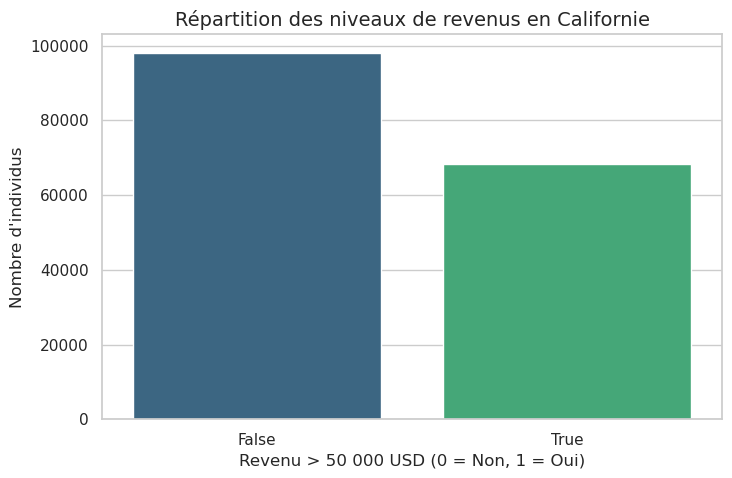

In [18]:
plt.figure(figsize=(8, 5)) # nouvelle figure
# Diagramme en barres comptant le nombre d'occurences de 0 et 1 pour PINCP
# 1 = revenu > 50 000 USD, 0 = revenu < 50 000 USD
ax = sns.countplot(data=df, x='PINCP', palette='viridis')
plt.title("Répartition des niveaux de revenus en Californie", fontsize=14)
plt.xlabel("Revenu > 50 000 USD (0 = Non, 1 = Oui)", fontsize=12)
plt.ylabel("Nombre d'individus", fontsize=12)
plt.show()

**Impact de l'âge sur le revenu**

/tmp/ipykernel_140626/3224588984.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='PINCP', y='AGEP', palette='Set2')


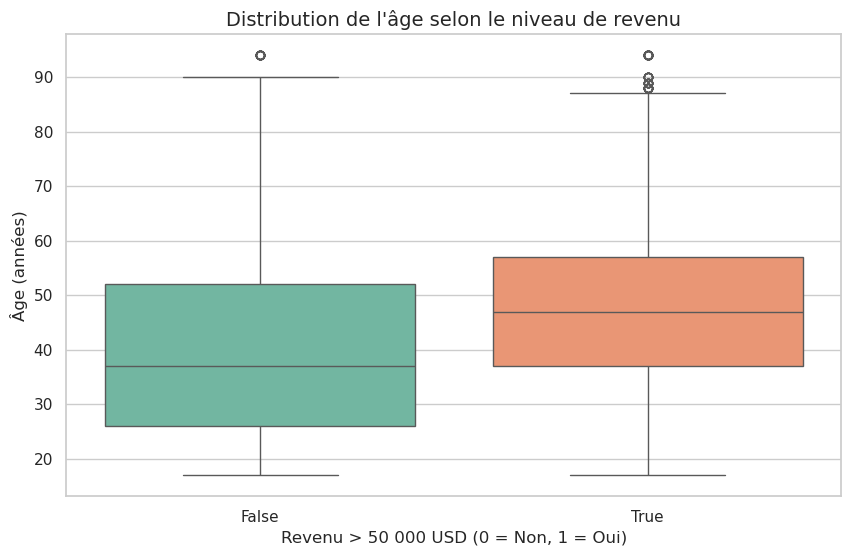

In [19]:
plt.figure(figsize=(10, 6))
# Boxplot qui croise la classe de revenu (X) et l'âge (Y)
sns.boxplot(data=df, x='PINCP', y='AGEP', palette='Set2')
plt.title("Distribution de l'âge selon le niveau de revenu", fontsize=14)
plt.xlabel("Revenu > 50 000 USD (0 = Non, 1 = Oui)", fontsize=12)
plt.ylabel("Âge (années)", fontsize=12)
plt.show()

**Niveau d'études et accès aux tranches de revenus les plus élevées**

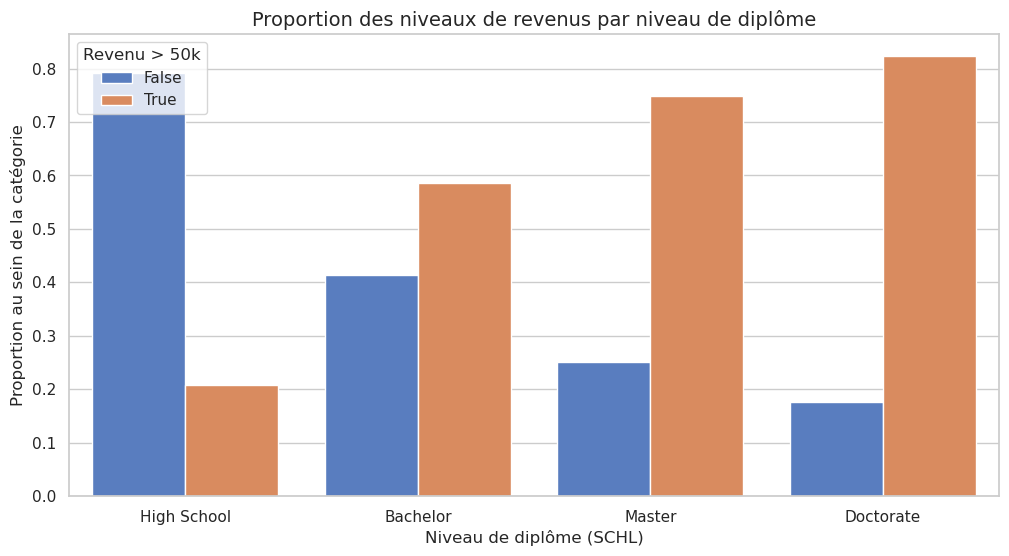

In [20]:
plt.figure(figsize=(12, 6))
# Dictionnaire associant les codes numériques de scolarité à des libellés
edu_mapping = {16: 'High School', 21: 'Bachelor', 22: 'Master', 24: 'Doctorate'}
# Filtre le DataFrame pour ne garder que les lignes qui correspondent aux niveaux de diplôme du dictionnaire
df_subset = df[df['SCHL'].isin(edu_mapping.keys())].copy()
# Colonne qui utilise le dicitonnaire pour traduire les codes des niveaux de scolarité en texte
df_subset['Education'] = df_subset['SCHL'].map(edu_mapping)

# Calcule les proportions de chaque niveau d'études
prop_df = df_subset.groupby('Education')['PINCP'].value_counts(normalize=True).rename('Proportion').reset_index()

# Barplot affichant les propotions (Y) par diplôme (X), séparées par couleur selon le revenu
sns.barplot(data=prop_df, x='Education', y='Proportion', hue='PINCP', palette='muted',
            order=['High School', 'Bachelor', 'Master', 'Doctorate'])
plt.title("Proportion des niveaux de revenus par niveau de diplôme", fontsize=14)
plt.xlabel("Niveau de diplôme (SCHL)", fontsize=12)
plt.ylabel("Proportion au sein de la catégorie", fontsize=12)
plt.legend(title="Revenu > 50k", loc='upper left')
plt.show()

**Disparités de genre**

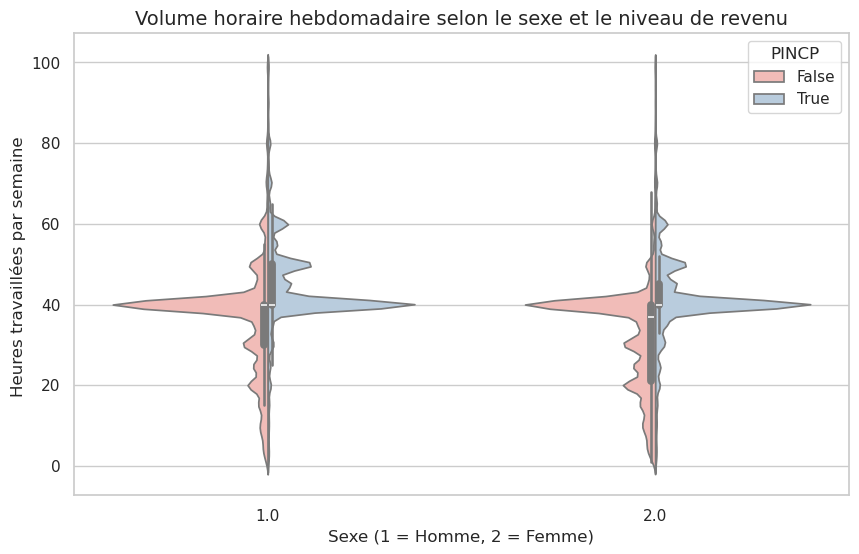

In [21]:
plt.figure(figsize=(10, 6))
# Diagramme en violon pour croiser le sexe (X) et les heures travaillées (Y), séparés selon le revenu
sns.violinplot(data=df, x='SEX', y='WKHP', hue='PINCP', split=True, palette='Pastel1')
plt.title("Volume horaire hebdomadaire selon le sexe et le niveau de revenu", fontsize=14)
plt.xlabel("Sexe (1 = Homme, 2 = Femme)", fontsize=12)
plt.ylabel("Heures travaillées par semaine ", fontsize=12)
plt.show()

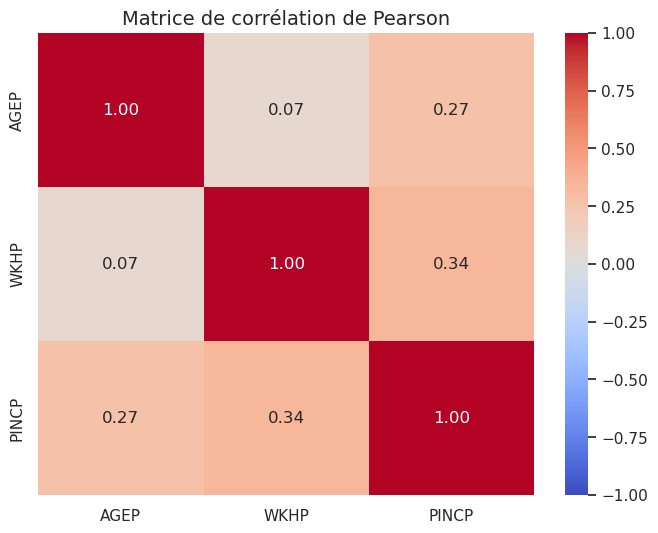

In [22]:
plt.figure(figsize=(8, 6))
# Liste des variables continues analysées
cols_num = ['AGEP', 'WKHP', 'PINCP']
# Matrice de corrélation linéaire de Pearson entre ces colonnes
corr_matrix = df[cols_num].corr(method='pearson')
# Heatmap de la matrice
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice de corrélation de Pearson", fontsize=14)
plt.show()